In [1]:
%%bash
sudo apt-get update &> /dev/null
sudo apt-get install -y wxcairo pciutils 1> /dev/null
curl -fsSL https://ollama.com/install.sh | sh

E: Unable to locate package wxcairo
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...


>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [2]:
%%bash

pip install \
    --extra-index-url=https://pypi.nvidia.com -q \
    torch==2.10.0 \
    polars==2.1.0  \
    librmm-cu12==26.10 \
    spacy \
    seaborn==0.13.2 \
    ollama==0.6.2 \
    matplotlib==3.10.9 \
    pyarrow==24.0.0 \
    torch==2.10.0 \
    typing-extensions \
    pyarrow==24.0.0 \
    textstat==0.7.13 \
    transformers==5.10.2 \
    click>=8.0.4 \
    click-completion>=0.5.2 \
    statsmodels

spacy download en_core_web_sm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchaudio 2.8.0+cu128 requires torch==2.8.0, but you have torch 2.10.0 which is incompatible.
torchvision 0.23.0+cu128 requires torch==2.8.0, but you have torch 2.10.0 which is incompatible.


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 28.9 MB/s  0:00:00m0:00:010:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [1]:
import os
import re
import json
import numpy
import polars
import ollama
import spacy
import seaborn
import textstat
import multiprocessing

from spacy.language import Language
from spacy.tokens import Doc
from pathlib import Path
from itertools import permutations
from matplotlib import pyplot
from capstone_lib import CapstoneLib 

os.chdir(f"{CapstoneLib.PROJ_ROOT}/uol_capstone_project")

polars.thread_pool_size()


200

In [4]:
# 1  Cuad Data loading
PATH_CUAD_PARQUET = Path(CapstoneLib.PROJ_ROOT).rglob("**/*/0001_cuad_dataset.parquet")
PATH_CUAD_JSON = Path(CapstoneLib.PROJ_ROOT).rglob("**/*/CUADv1.json")

CUAD_PARQUET = next(PATH_CUAD_PARQUET, None)
CUAD_JSON = next(PATH_CUAD_JSON, None)


if os.path.exists(CUAD_PARQUET):
    cuad_legal = CapstoneLib.load_parquet(CUAD_PARQUET)

    with open(CUAD_JSON) as cuad:
        cuad_json = json.load(cuad.buffer)

    legal_pieces = {}

    for data in cuad_json.get("data"):
        full_context = ""
        for paragraph in data.get("paragraphs"):
            if context := paragraph.get("context", ""):
                full_context += context
        legal_pieces[data.get("title")] = full_context

    cuad_legal = polars.DataFrame(legal_pieces)
    cuad_legal = cuad_legal.transpose(include_header=True)
    cuad_legal.columns = ["title", "paragraphs"]

    cuad_legal.write_parquet("parquet_files/0001_cuad_dataset.parquet")


In [2]:
# 2 Cuad data parsing

# Here we are trying to load cached file if it exists, otherwise we will need to reprocess everything
PATH_EXTRACTED_SENTENCES = Path(CapstoneLib.PROJ_ROOT).rglob("**/*/0002_cuad_dataset.parquet")
CUAD_EXTRACTED = next(PATH_EXTRACTED_SENTENCES, "non_existent.parquet")

nlp = spacy.blank("en")
nlp.add_pipe("sentencizer")
nlp.add_pipe("parser")
nlp.initialize()

if os.path.exists(CUAD_EXTRACTED):
    cuad_legal = polars.read_parquet(CUAD_EXTRACTED)
else:
    cuad_legal = cuad_legal.with_columns(
        polars.col("paragraphs").map_elements(
            lambda paragraph: [p.text for p in nlp(paragraph).sents],
            return_dtype=polars.List(polars.String)
        ).alias("sentences")
    )
    cuad_legal = (
        cuad_legal
            .explode("sentences", empty_as_null=False)
            .filter(
                polars.col("sentences").is_not_null() & 
                (polars.col("sentences").str.len_chars() > 0)
            )
            .with_columns(
                polars.col("sentences").map_elements(
                    lambda text: re.sub(r"\s{2,}"," ", text)
                )
            )
            .with_columns(
                polars.col("sentences").str.strip_chars()
            )
    )
    cuad_legal.write_parquet("parquet_files/0002_cuad_dataset.parquet")

In [2]:
# 3 Applying metrics

# Here we are trying to load cached file if it exists, otherwise we will need to reprocess everything
PATH_APPLIED_METRICS = Path(CapstoneLib.PROJ_ROOT).rglob("**/*/0003_cuad_dataset.parquet")
CUAD_EXTRACTED = next(PATH_APPLIED_METRICS, "non_existent.parquet")

if os.path.exists(CUAD_EXTRACTED):
    cuad_legal = polars.read_parquet(CUAD_EXTRACTED)
else:
    cuad_legal = CapstoneLib.apply_metrics(cuad_legal)
    cuad_legal.write_parquet("parquet_files/0003_cuad_dataset.parquet")


# Some negative values were spotted in the complexity score due to simple mostly single words
cuad_legal.filter(polars.col("complexity_score") < 0)

title,paragraphs,sentences,fre,fkgl,fog,dale_chall,lix,complexity_score
str,str,str,f64,f64,f64,f64,f64,f64
"""WHITESMOKE,INC_11_08_2011-EX-1…","""Exhibit 10.26 CONFIDENTIAL …","""Deactivation.""",-217.18,43.8,40.4,19.4761,101.0,-2.50078
"""KIROMICBIOPHARMA,INC_05_11_202…","""Exhibit 10.23 Corporate Addres…","""Confidentiality. """"",-386.38,67.4,40.4,19.4761,101.0,-31.62078
"""KIROMICBIOPHARMA,INC_05_11_202…","""Exhibit 10.23 Corporate Addres…","""Severability.""",-217.18,43.8,40.4,19.4761,101.0,-2.50078
"""PACIRA PHARMACEUTICALS, INC. -…","""Exhibit 10.13 Confidential Ma…","""7.4 Confidentiality.""",-133.595,32.39,20.8,19.5257,52.0,-1.77586
"""PACIRA PHARMACEUTICALS, INC. -…","""Exhibit 10.13 Confidential Ma…","""Nonnegotiability, Nontransfera…",-302.795,55.99,40.8,19.5257,102.0,-16.89586
…,…,…,…,…,…,…,…,…
"""MERITLIFEINSURANCECO_06_19_202…","""Exhibit 10(xiv) MASTER SERVIC…","""Severability.""",-217.18,43.8,40.4,19.4761,101.0,-2.50078
"""PerformanceSportsBrandsInc_201…","""ENDORSEMENT AGREEMENT enter…","""Termination/Remedies.""",-301.78,55.6,40.4,19.4761,101.0,-17.06078
"""PerformanceSportsBrandsInc_201…","""ENDORSEMENT AGREEMENT enter…","""Indemnification.""",-301.78,55.6,40.4,19.4761,101.0,-17.06078


In [3]:
# So I removed all the lower score to avoid unecessary noise during the analysis

cuad_legal = cuad_legal.filter(
    (
        polars.col("sentences")
        .str.split(" ")
        .list.len()
        >= 3
    )
    & polars.col("fre").is_finite()
    & polars.col("fkgl").is_finite()
    & polars.col("fog").is_finite()
    & polars.col("dale_chall").is_finite()
    & polars.col("lix").is_finite()
)

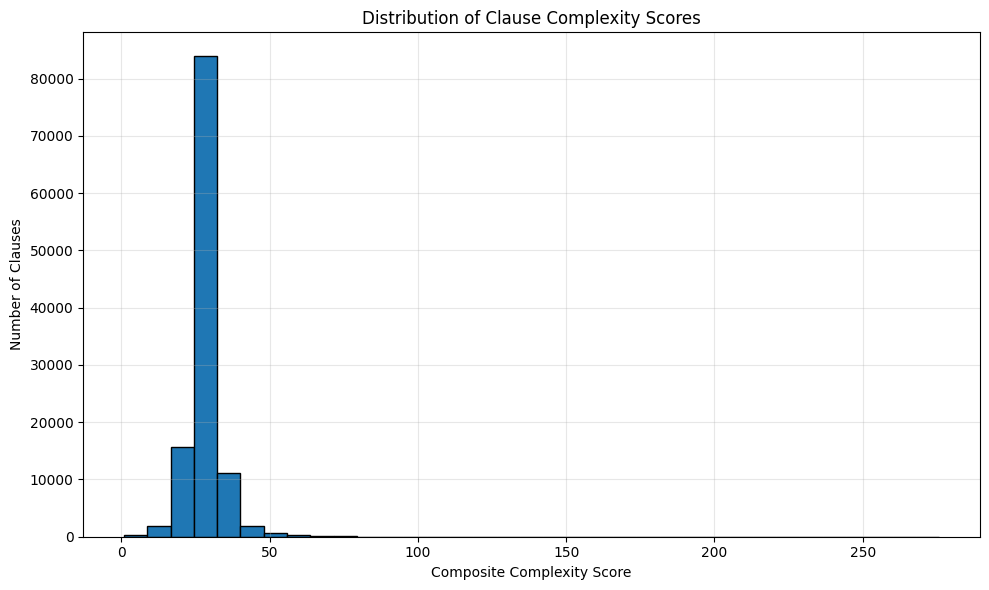

In [32]:
# 4 plots

# Figure — Complexity Score Distribution

# Figure presents the distribution of the composite complexity scores calculated 
# for all extracted clauses. The complexity score was derived from five readability
# and lexical complexity metrics: Flesch Reading Ease (FRE), Flesch-Kincaid Grade Level
# (FKGL), Gunning Fog Index, Dale-Chall Readability Score, and LIX. These metrics were
# normalised and combined into a single score to provide an overall measure of
#linguistic complexity.
# The distribution illustrates the variability in readability across the contractual
# clauses contained in the CUAD dataset. While a large proportion of clauses exhibit
# moderate complexity, a subset of clauses receives substantially higher complexity
# scores, highlighting particularly challenging legal language. This observation
#supports the need for a selective simplification strategy, as not all clauses require
#the same level of intervention.
# The complexity score distribution also provides evidence that the dataset contains a
# sufficiently diverse range of readability levels, making it an appropriate corpus for
# evaluating the effectiveness of Large Language Models in simplifying legal text.
# The highest-scoring clauses identified in this analysis were subsequently selected
#for simplification and further evaluation.

import matplotlib.pyplot as plt

complexity_scores = (
    filtered_pos_score_cuad_legal
    .filter(polars.col("complexity_score") > 0)
    .select("complexity_score")
    .to_series()
    .to_list()
)

plt.figure(figsize=(10, 6))

plt.hist(
    complexity_scores,
    bins=35,
    edgecolor="black"
)

plt.title("Distribution of Clause Complexity Scores")
plt.xlabel("Composite Complexity Score")
plt.ylabel("Number of Clauses")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

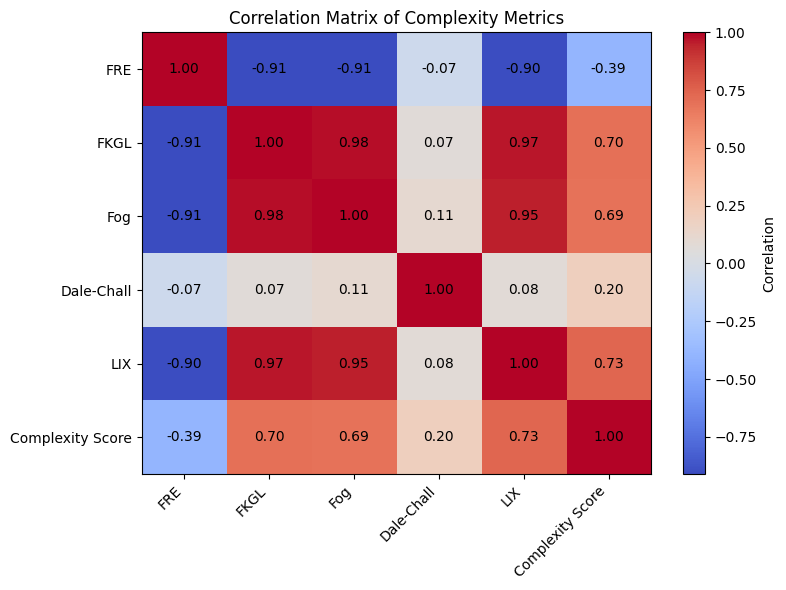

In [33]:
# Figure Correlation Matrix of Readability and Complexity Metrics

# Figure presents the correlation matrix for the five readability metrics used in
# this research together with the composite complexity score. The purpose of this
# analysis is to examine the relationships between individual metrics and determine
# whether they capture similar or complementary aspects of textual complexity.

# As expected, Flesch Reading Ease demonstrates negative correlations with the
# remaining metrics because higher FRE values indicate easier text, whereas higher
# values for FKGL, Gunning Fog, Dale-Chall, and LIX indicate increased complexity.
# Strong positive correlations between FKGL and Gunning Fog suggest that both
# metrics respond similarly to increases in sentence length and vocabulary difficulty.
# Likewise, positive correlations between Dale-Chall and LIX indicate that lexical
# complexity contributes significantly to the perceived difficulty of legal clauses.

# The relationship between the individual metrics and the composite complexity score
# provides additional validation of the scoring methodology. Metrics displaying stronger
# correlations with the composite score exert a greater influence on overall complexity
# rankings, while weaker correlations indicate that the metric captures a distinct
# dimension of readability. Collectively, the results suggest that the selected metrics
# provide complementary information, supporting the use of a combined complexity score
# for identifying clauses most suitable for simplification.

# The findings presented in Figures 5.1 and 5.2 establish the quantitative basis for
# clause selection and provide justification for the subsequent simplification and
# evaluation stages of the research.

import matplotlib.pyplot as plt

metrics = (
    filtered_pos_score_cuad_legal
    .filter(polars.col("complexity_score") > 0)
    .select(
        [
            "fre",
            "fkgl",
            "fog",
            "dale_chall",
            "lix",
            "complexity_score"
        ]
    )
    .to_pandas()
)

correlation_matrix = metrics.corr()

metric_names = [
    "FRE",
    "FKGL",
    "Fog",
    "Dale-Chall",
    "LIX",
    "Complexity Score"
]

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(metric_names)),
    metric_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(metric_names)),
    metric_names
)

# Add values inside squares
for i in range(len(metric_names)):
    for j in range(len(metric_names)):
        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            color="black"
        )

plt.title("Correlation Matrix of Complexity Metrics")

plt.tight_layout()
plt.show()

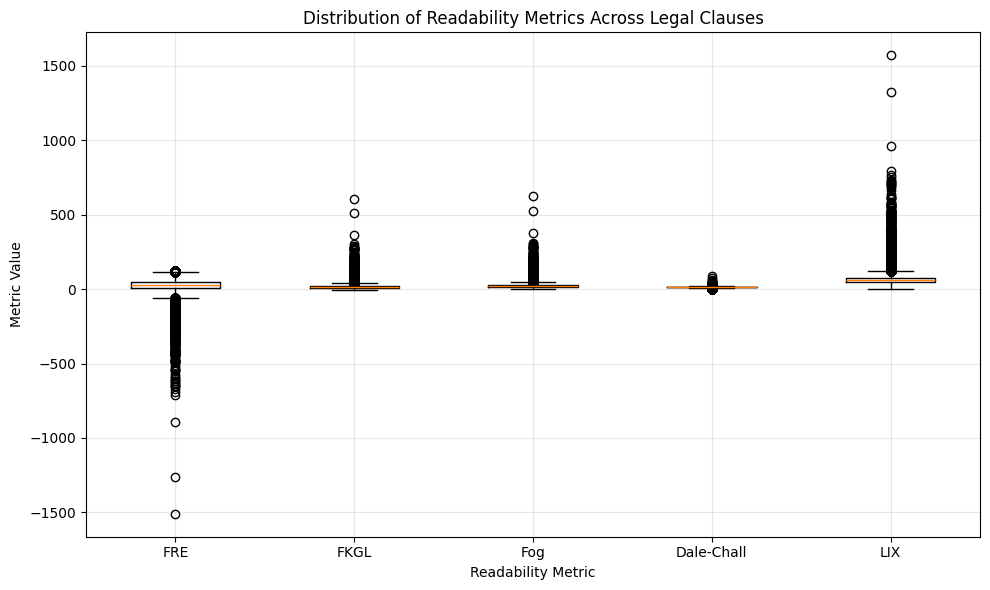

In [37]:
# Distribution of Individual Readability Metrics

# Figure illustrates the distribution of the five readability metrics used
# to assess the linguistic complexity of clauses extracted from the CUAD dataset.
# Boxplots are used to visualise the spread, central tendency, and presence of
# outliers for each metric.

# The results demonstrate that legal clauses exhibit considerable variation in
# readability and lexical complexity. While some clauses receive relatively moderate
# scores, others are characterised by substantially higher levels of complexity,
# reflecting the diversity of drafting styles present within contractual documents.
# The presence of numerous outliers further suggests that a subset of clauses is
# significantly more difficult to understand than the majority of the corpus.

# Differences in the distributions of the metrics indicate that each measure captures
# a distinct aspect of textual complexity. Flesch Reading Ease focuses on reading
# difficulty, whereas Flesch–Kincaid Grade Level and Gunning Fog estimate the
# educational level required for comprehension. Dale-Chall and LIX place greater
# emphasis on vocabulary complexity and the use of longer words. The variation observed
# across the metrics supports the decision to combine multiple measures into a single
# composite complexity score rather than relying on any individual metric in isolation.


import matplotlib.pyplot as plt

metrics = [
    "fre",
    "fkgl",
    "fog",
    "dale_chall",
    "lix"
]

data = [
    filtered_pos_score_cuad_legal[column].to_list()
    for column in metrics
]

plt.figure(figsize=(10, 6))

plt.boxplot(data)

plt.xticks(
    range(1, 6),
    [
        "FRE",
        "FKGL",
        "Fog",
        "Dale-Chall",
        "LIX"
    ]
)

plt.title("Distribution of Readability Metrics Across Legal Clauses")
plt.xlabel("Readability Metric")
plt.ylabel("Metric Value")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

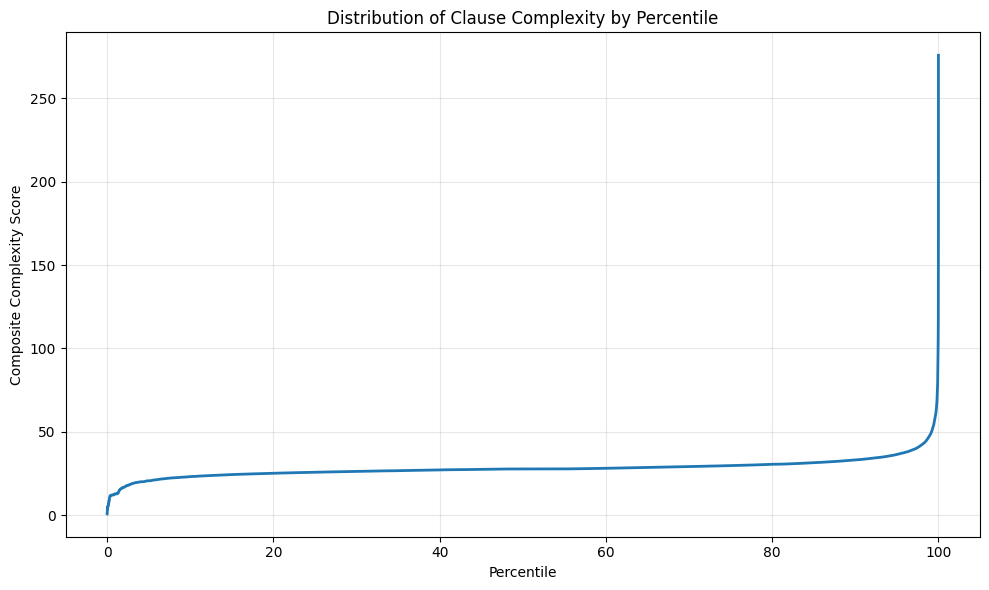

In [38]:
# 5.4 Relationship Between Flesch Reading Ease and Flesch-Kincaid Grade Level

# Figure 5.4 presents the distribution of composite complexity scores across clause
# percentiles. The results demonstrate that complexity is not uniformly distributed
# throughout the dataset. While a large proportion of clauses exhibit relatively
# similar readability levels, the highest percentiles contain substantially more
# complex clauses.

# The sharp increase observed towards the upper end of the distribution indicates
# the presence of a subset of clauses that are considerably more difficult than the
# majority of the corpus. These clauses represent the greatest barriers to
# comprehension for non-expert readers and therefore constitute appropriate candidates
# for simplification.

# This finding supports the decision to adopt a targeted simplification strategy
# rather than processing all clauses equally. By focusing on clauses located in the
# upper complexity percentiles, the evaluation can more effectively measure the ability
# of Large Language Models to reduce linguistic complexity while preserving legal
# meaning.

import matplotlib.pyplot as plt
import numpy

scores = (
    filtered_pos_score_cuad_legal["complexity_score"]
    .sort()
    .to_list()
)

percentiles = numpy.linspace(0, 100, len(scores))

plt.figure(figsize=(10, 6))
plt.plot(percentiles, scores, linewidth=2)
plt.title("Distribution of Clause Complexity by Percentile")
plt.xlabel("Percentile")
plt.ylabel("Composite Complexity Score")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

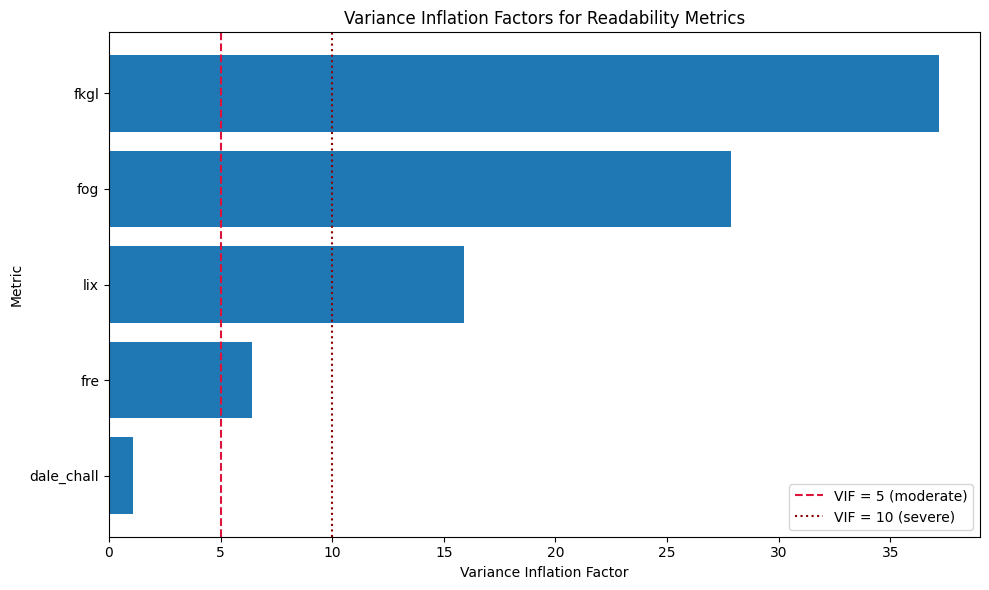

In [42]:
# Variance Inflation Factor

# text....


import matplotlib.pyplot as plt
import pandas
from statsmodels.stats.outliers_influence import variance_inflation_factor

features = (
    filtered_pos_score_cuad_legal
    .select(
        [
            "fre",
            "fkgl",
            "fog",
            "dale_chall",
            "lix"
        ]
    )
    .drop_nulls()
    .to_pandas()
)

vif_df = pandas.DataFrame(
    {
        "Metric": features.columns,
        "VIF": [
            variance_inflation_factor(
                features.values,
                i
            )
            for i in range(features.shape[1])
        ]
    }
)

vif_df = vif_df.sort_values(
    "VIF",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    vif_df["Metric"],
    vif_df["VIF"]
)

plt.axvline(
    5,
    color="crimson",
    linestyle="--",
    label="VIF = 5 (moderate)"
)

plt.axvline(
    10,
    color="darkred",
    linestyle=":",
    label="VIF = 10 (severe)"
)

plt.xlabel("Variance Inflation Factor")
plt.ylabel("Metric")

plt.title(
    "Variance Inflation Factors for Readability Metrics"
)

plt.legend()

plt.tight_layout()
plt.show()


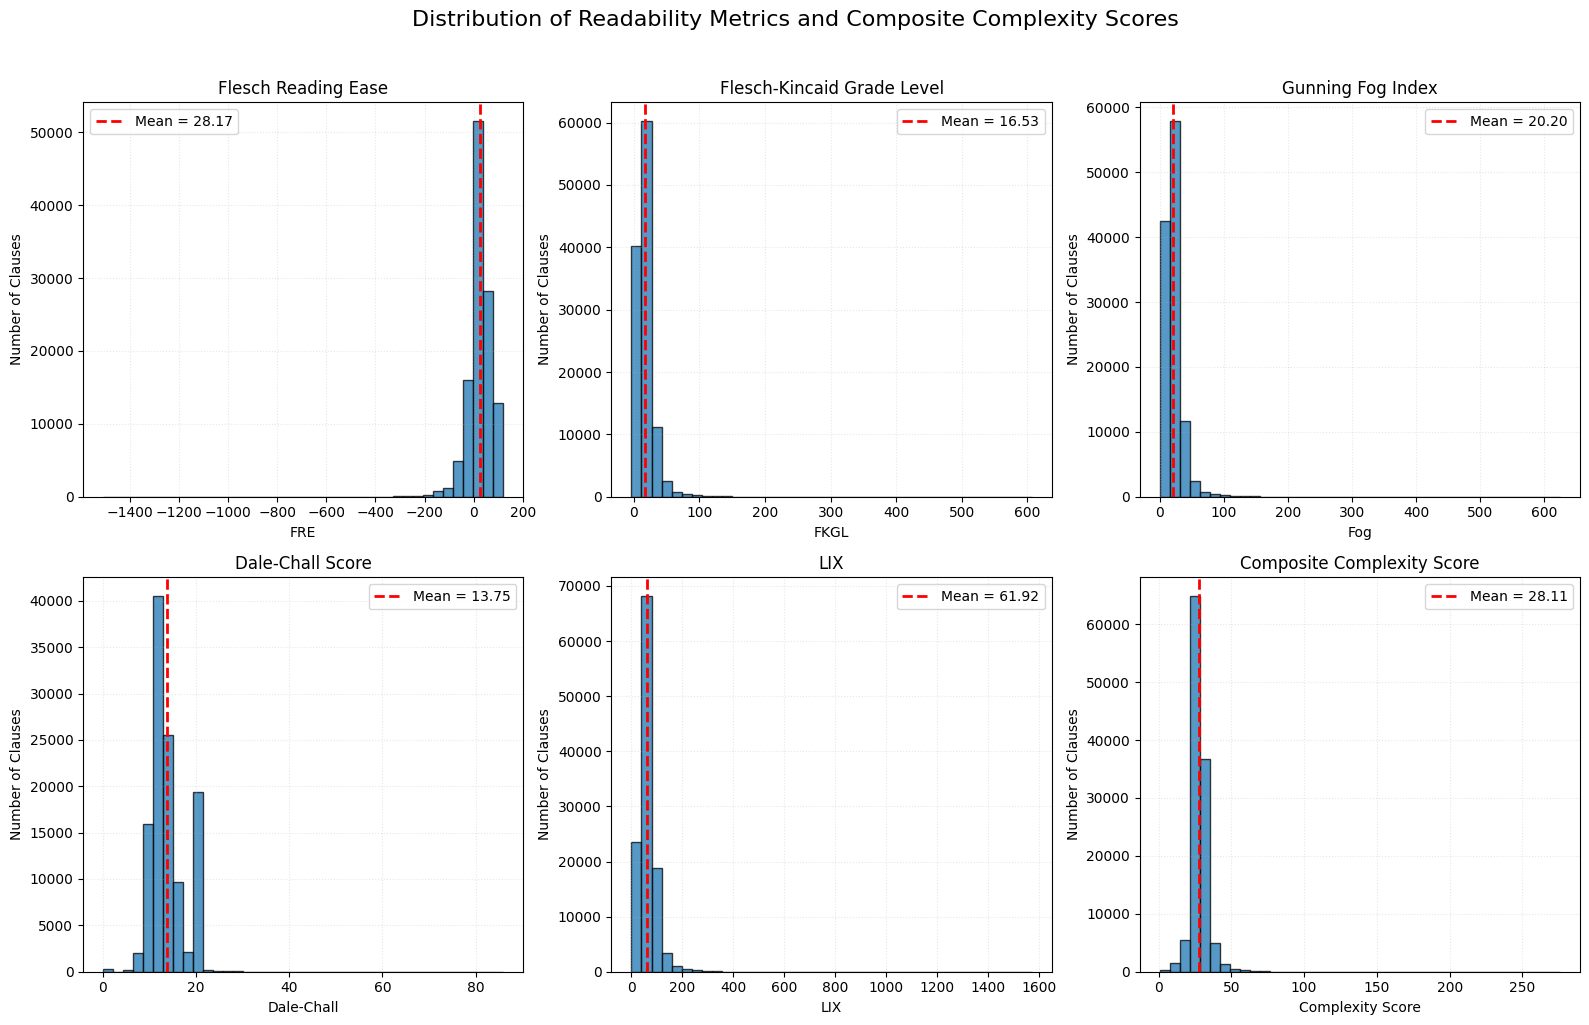

In [43]:
# 5.5 Distribution of Readability Metrics and Composite Complexity Scores

# Figure 5.5 presents the distributions of the five readability metrics used throughout
# this research, together with the resulting composite complexity score. The figure provides
# an overview of the linguistic characteristics of the legal clauses extracted from the CUAD
# dataset and illustrates the variability present within contractual language.

# The distributions reveal substantial differences in readability across the corpus.
# Flesch Reading Ease exhibits a broad range of values, indicating that while some clauses are
# relatively accessible, others are considerably more difficult to read. Similar variation can be
# observed in Flesch-Kincaid Grade Level and Gunning Fog Index scores, suggesting that the educational
# level required to understand legal clauses differs significantly throughout the dataset.

# The lexical measures, Dale-Chall and LIX, also demonstrate considerable dispersion. These results
# indicate that legal clauses frequently contain specialised vocabulary and long words, both of which
# contribute to increased reading difficulty for non-expert audiences. The presence of extreme values
# across several metrics further highlights the existence of particularly complex clauses within the corpus.

# The distribution of the composite complexity score reflects the combined effect of all five readability
# measures. While most clauses are concentrated around the centre of the distribution, a smaller subset
# exhibits substantially higher complexity scores. These high-scoring clauses represent the most linguistically
# demanding provisions identified during the analysis and provide a clear justification for the targeted
# simplification strategy adopted in this study.

# Overall, the results demonstrate that legal language exhibits significant variability in readability and
# complexity. This finding supports the use of a quantitative selection process, as the most complex clauses
# can be objectively identified and prioritised for simplification. The complexity scores generated in this
# stage are subsequently used to rank clauses and select candidates for LLM-based rewriting in the following
# stages of the evaluation.


import matplotlib.pyplot as plt

metrics = [
    "fre",
    "fkgl",
    "fog",
    "dale_chall",
    "lix",
    "complexity_score"
]

titles = [
    "Flesch Reading Ease",
    "Flesch-Kincaid Grade Level",
    "Gunning Fog Index",
    "Dale-Chall Score",
    "LIX",
    "Composite Complexity Score"
]

xlabels = [
    "FRE",
    "FKGL",
    "Fog",
    "Dale-Chall",
    "LIX",
    "Complexity Score"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, (metric, title, xlabel) in enumerate(
    zip(metrics, titles, xlabels)
):

    values = (
        filtered_pos_score_cuad_legal
        .select(metric)
        .drop_nulls()
        .to_series()
        .to_list()
    )

    axes[i].hist(
        values,
        bins=40,
        edgecolor="black",
        alpha=0.75
    )

    mean_value = sum(values) / len(values)

    axes[i].axvline(
        mean_value,
        color="red",
        linestyle="--",
        linewidth=2,
        label=f"Mean = {mean_value:.2f}"
    )

    axes[i].set_title(title)
    axes[i].set_xlabel(xlabel)
    axes[i].set_ylabel("Number of Clauses")
    axes[i].legend()
    axes[i].grid(
        alpha=0.3,
        linestyle=":"
    )

fig.suptitle(
    "Distribution of Readability Metrics and Composite Complexity Scores",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


In [ ]:
# LLM Assessment
# probably try 3 different prompts
from tqdm.auto import tqdm
from concurrent.futures import ThreadPoolExecutor


# Here we are trying to load cached file if it exists, otherwise we will need to reprocess everything
PATH_APPLIED_LLM = Path(CapstoneLib.PROJ_ROOT).rglob("**/*/0004_cuad_llm_simplified.parquet")
CUAD_EXTRACTED = next(PATH_APPLIED_LLM, "non_existent.parquet")

if os.path.exists(CUAD_EXTRACTED):
    cuad_legal_evaluation = polars.read_parquet(CUAD_EXTRACTED)
else:
    PROMPT = Path(CapstoneLib.PROJ_ROOT).rglob("**/*/clause_simplifier*.md")
    
    cuad_legal_evaluation = (
        cuad_legal
        .with_row_index("id")
        .sample(
            n=500,
            seed=42
        )
    )

    round = 1
    while prompt_path := next(PROMPT, None):
        tqdm_bar = tqdm(
            total=cuad_legal_evaluation.height,
            desc="Gemma4 Simplification"
        )
        cuad_legal_evaluation = cuad_legal_evaluation.with_columns(
            polars.col("sentences").map_elements(
                lambda sentence: CapstoneLib.llm_call_with_progress_bar(
                    tqdm_bar, sentence, prompt_path
                ),
                return_dtype=polars.String,
                strategy="threading"
            ).alias(f"gemma4_rnd{round}")
        )
        round += 1
        tqdm_bar.close()

    cuad_legal_evaluation.write_parquet("parquet_files/0004_cuad_llm_simplified.parquet")


Gemma4 Simplification:   0%|          | 0/500 [00:00<?, ?it/s]

Gemma4 Simplification:   0%|          | 0/500 [00:00<?, ?it/s]

Gemma4 Simplification:   0%|          | 0/500 [00:00<?, ?it/s]

In [8]:
cuad_legal_evaluation

In [8]:
cuad_legal_evaluation = CapstoneLib.apply_metrics(cuad_legal_evaluation, "gemma4_rnd1")

In [ ]:
cuad_legal_evaluation.join(
    cuad_legal,
    left_on="id",
    right_on="id",
    how="inner",
    suffix="r"
)

In [9]:
cuad_legal_evaluation

id,title,paragraphs,sentences,fre,fkgl,fog,dale_chall,lix,complexity_score,gemma4_rnd1
u32,str,str,str,f64,f64,f64,f64,f64,f64,str
82881,"""Monsanto Company - SECOND A_R …","""Exhibit 10.14(a) SECOND AMEND…","""(b) Compliance with Monsanto's…",54.701429,7.368571,14.228571,15.262271,49.857143,28.283597,"""You must follow Monsanto's Cod…"
32450,"""JINGWEIINTERNATIONALLTD_10_04_…","""INTELLECTUAL PROPERTY AGREEMEN…","""Confidentiality 4.1 Party B sh…",-10.204194,22.383871,22.722581,12.305068,66.483871,22.738239,"""Party B must keep all informat…"
100142,"""NOVOINTEGRATEDSCIENCES,INC_12_…","""Exhibit 10.1 JOINT VENTURE AGR…","""The Parties shall record such …",60.191765,9.087059,13.858824,9.123818,46.411765,27.734646,"""The agreement must be written …"
71363,"""TELKOMSALTD_01_30_2003-EX-10-L…","""-1 - …","""The Projected Resolution Time …",44.97,10.713333,16.666667,11.749167,55.0,27.819833,"""This clause defines the projec…"
80765,"""CnsPharmaceuticalsInc_20200326…","""Exhibit 10.1 Development Agree…","""8-K, 3/26/2020 ARTICLE 8 INDEM…",1.065227,25.407929,29.90101,15.182912,82.833333,30.878082,"""WPD must protect CNS from thir…"
…,…,…,…,…,…,…,…,…,…,…
25827,"""ACCURAYINC_09_01_2010-EX-10.31…","""Exhibit 10.31 PURSUANT TO 1…","""Updated price lists shall not …",40.289655,14.844138,19.875862,12.697659,53.137931,28.169049,"""Updated price lists do not aff…"
39604,"""CERES,INC_01_25_2012-EX-10.20-…","""Exhibit 10.20 Pages where con…","""Further, TRAIT FEES, if any, s…",87.997273,3.718182,4.4,9.923918,20.090909,25.226056,"""Any TRAIT FEES must be added t…"
46857,"""CHANGEPOINTCORP_03_08_2000-EX-…","""CONFIDENTIAL TREATMENT - REDAC…","""2.10 PREFERRED RELATIONSHIP.""",6.39,13.113333,14.533333,19.5753,69.666667,24.655727,"""Please provide the full text o…"
